# Checkpoint — Dimensie reductie

Dit notebook wordt automatisch gecheckt via pytest (GitHub Actions). De checks voeren je notebook uit en valideren of bepaalde variabelen bestaan en binnen de verwachte ranges vallen. **Je krijgt geen hints in de foutmeldingen: het is aan jou om correct werkende code te schrijven.**

## BELANGRIJK: gebruik exact de genoemde variabelennamen

De checks zoeken volgende variabelen in je notebook. Andere namen worden niet gezien:

- `n_components_secom` — aantal PCA-componenten dat 95% van de variantie behoudt voor SECOM (int)
- `reduction_pct_secom` — procent datareductie voor SECOM (float)
- `X_pca_secom` — de gereduceerde data van SECOM (evenveel rijen als de oorspronkelijke data, `n_components_secom` kolommen)
- `n_components_steel` — aantal PCA-componenten dat 95% van de variantie behoudt voor Steel Plates (int)
- `reduction_pct_steel` — procent datareductie voor Steel Plates (float)
- `X_pca_steel` — de gereduceerde data van Steel Plates
- `n_components_aps` — aantal PCA-componenten dat 95% van de variantie behoudt voor APS (int)
- `reduction_pct_aps` — procent datareductie voor APS (float)
- `X_pca_aps` — de gereduceerde data van APS
- `antwoord_scaling` — meerkeuzevraag 1: `"A"`, `"B"`, `"C"` of `"D"`
- `antwoord_95` — meerkeuzevraag 2: `"A"`, `"B"`, `"C"` of `"D"`

Gebruik voor elke dataset `PCA(n_components=0.95)` op de **gestandaardiseerde** data (met `StandardScaler`). De datareductie bereken je als `(1 - aantal_componenten / oorspronkelijk_aantal_features) * 100`.

De datasets staan lokaal in `data/` (er wordt niets gedownload).


## Oefening 1 — SECOM

De SECOM-dataset bevat 590 sensormetingen van halfgeleiderproductie. Het bestand bevat veel ontbrekende waarden; vul ze in met het kolomgemiddelde.

Pas PCA toe zodat **95% van de variantie behouden blijft**. Bewaar het aantal componenten in `n_components_secom`, de gereduceerde data in `X_pca_secom` en de procentuele datareductie in `reduction_pct_secom`.


In [2]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Pad naar bestanden
data_path = "data/secom/secom.data"
labels_path = "data/secom/secom_labels.data"

# Dataset laden (spatie is de separator in SECOM)
X = pd.read_csv(data_path, sep="\\s+", header=None)
y = pd.read_csv(labels_path, sep="\\s+", header=None, usecols=[0])  # labels in eerste kolom

# Ontbrekende waarden invullen met het kolomgemiddelde
X = X.fillna(X.mean())

# Data standaardiseren
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [3]:
# TODO: pas PCA toe zodat 95% van de variantie behouden blijft.
# Bewaar het aantal componenten in n_components_secom, de gereduceerde
# data in X_pca_secom en de procentuele datareductie in reduction_pct_secom.
# Pas PCA toe zodat 95% van de variantie behouden blijft
pca = PCA(n_components=0.95)
X_pca_secom = pca.fit_transform(X_scaled)

# Bewaar het aantal componenten
n_components_secom = pca.n_components_

# Bereken de procentuele datareductie
oorspronkelijk_aantal_features = X.shape[1]
reduction_pct_secom = (1 - (n_components_secom / oorspronkelijk_aantal_features)) * 100

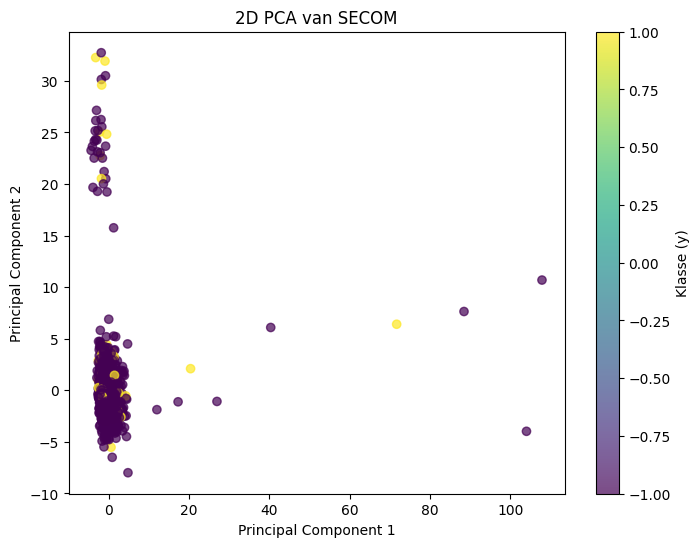

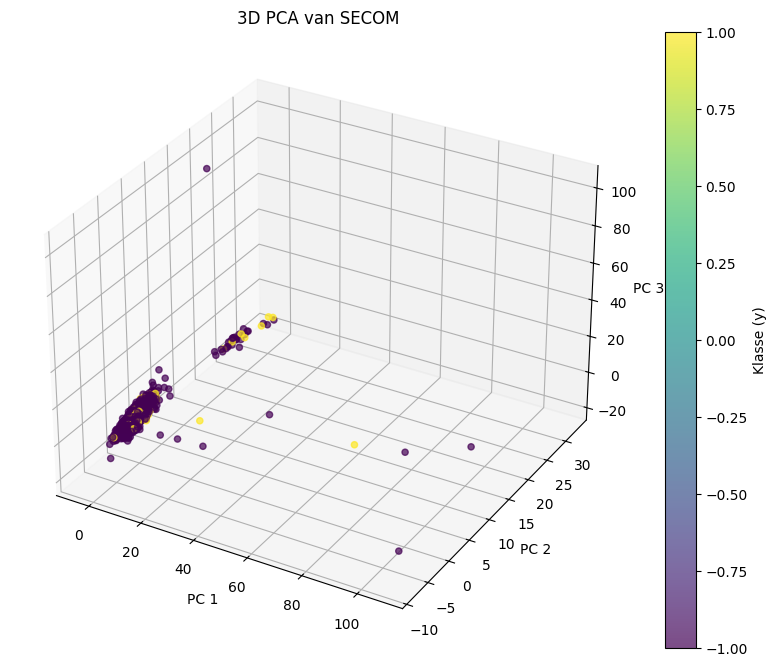

In [4]:
# TODO: maak een 2D- en 3D-plot van de voornaamste PCA-componenten van
# X_scaled (niet gecheckt, maar leerzaam). Tip: fit hiervoor opnieuw een
# PCA met n_components=2 en n_components=3 en kleur de punten met y.
# === 2D PLOT ===
# 1. Fit opnieuw een PCA, nu met exact 2 componenten
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

# 2. Maak de 2D grafiek
plt.figure(figsize=(8, 6))
# We pakken kolom 0 voor de X-as en kolom 1 voor de Y-as. c=y kleurt de punten op basis van je labels.
plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=y, cmap='viridis', alpha=0.7)
plt.title("2D PCA van SECOM")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Klasse (y)")
plt.show()


# === 3D PLOT ===
# 1. Fit opnieuw een PCA, nu met exact 3 componenten
pca_3 = PCA(n_components=3)
X_pca_3 = pca_3.fit_transform(X_scaled)

# 2. Maak de 3D grafiek
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d') # Dit activeert de 3D-modus
# Nu hebben we 3 kolommen nodig (0, 1 en 2) voor de X-, Y- en Z-as
scatter = ax.scatter(X_pca_3[:, 0], X_pca_3[:, 1], X_pca_3[:, 2], c=y, cmap='viridis', alpha=0.7)
ax.set_title("3D PCA van SECOM")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_zlabel("PC 3")
fig.colorbar(scatter, label="Klasse (y)")
plt.show()

## Oefening 2 — Steel Plates Faults

De Steel Plates Faults-dataset bevat 27 metingen van staalplaten. De kolomnamen staan in `data/steel_plates/Faults27x7_var`; de laatste 7 kolommen zijn binaire foutlabels.

Pas PCA toe zodat **95% van de variantie behouden blijft** op de 27 meetkolommen. Bewaar het aantal componenten in `n_components_steel`, de gereduceerde data in `X_pca_steel` en de procentuele datareductie in `reduction_pct_steel`.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Pad naar bestanden
data_path = "data/steel_plates/Faults.NNA"
names_path = "data/steel_plates/Faults27x7_var"

# Kolomnamen laden
with open(names_path, "r") as f:
    colnames = [line.strip() for line in f.readlines()]

# Data laden
df = pd.read_csv(data_path, sep="\\s+", header=None, names=colnames)

# Eerste 27 kolommen zijn de metingen, de laatste 7 zijn binaire foutlabels
X = df.iloc[:, :27]
y = df.iloc[:, 27:]

# Ontbrekende waarden invullen met het kolomgemiddelde
X = X.fillna(X.mean())

# Data standaardiseren
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [5]:
# TODO: pas PCA toe zodat 95% van de variantie behouden blijft.
# Bewaar het aantal componenten in n_components_steel, de gereduceerde
# data in X_pca_steel en de procentuele datareductie in reduction_pct_steel.
pca = PCA(n_components=0.95)
X_pca_steel = pca.fit_transform(X_scaled)

# Bewaar het aantal componenten
n_components_steel = pca.n_components_

# Bereken de procentuele datareductie
oorspronkelijk_aantal_features = X.shape[1]
reduction_pct_steel = (1 - (n_components_steel / oorspronkelijk_aantal_features)) * 100

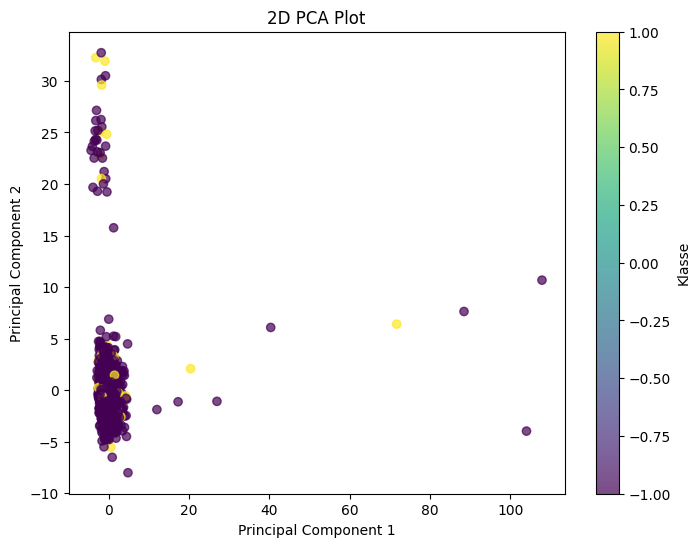

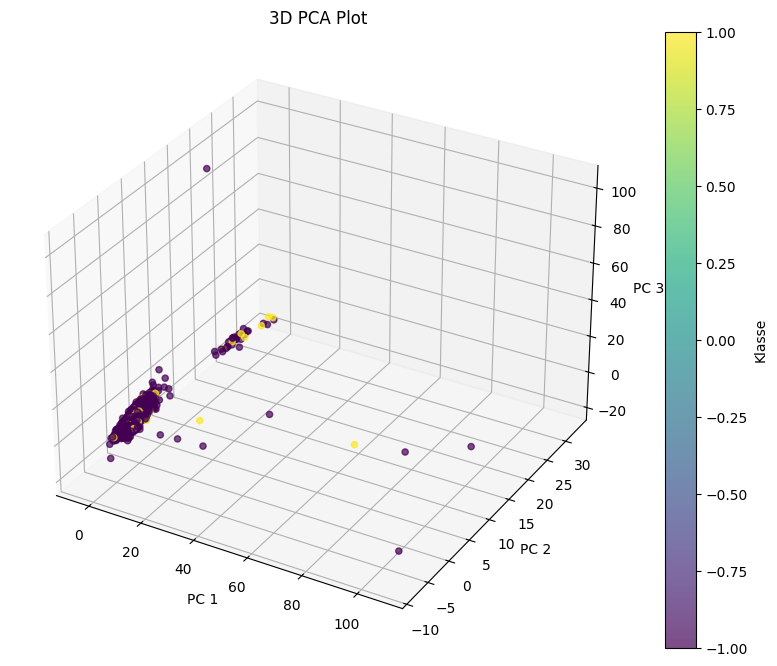

In [6]:
# TODO: maak een 2D- en 3D-plot van de voornaamste PCA-componenten van
# X_scaled (niet gecheckt, maar leerzaam).

# Zorg dat matplotlib is geïmporteerd (als dat nog niet was gedaan)
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# === 2D PLOT ===
# 1. Fit een PCA model met exact 2 componenten op X_scaled
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

# 2. Maak de 2D grafiek
plt.figure(figsize=(8, 6))
# Let op: ik ga ervan uit dat je variabele met labels 'y' heet. 
# Als je een error krijgt over 'y', verander dan 'c=y' naar een specifieke kleur, bijv. c='blue'
plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=y, cmap='viridis', alpha=0.7)
plt.title("2D PCA Plot")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Klasse")
plt.show()


# === 3D PLOT ===
# 1. Fit een PCA model met exact 3 componenten op X_scaled
pca_3 = PCA(n_components=3)
X_pca_3 = pca_3.fit_transform(X_scaled)

# 2. Maak de 3D grafiek
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_pca_3[:, 0], X_pca_3[:, 1], X_pca_3[:, 2], c=y, cmap='viridis', alpha=0.7)
ax.set_title("3D PCA Plot")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_zlabel("PC 3")
fig.colorbar(scatter, label="Klasse")
plt.show()


## Oefening 3 — APS Failure at Scania Trucks

De APS-dataset bevat 170 sensormetingen van vrachtwagens. De eerste 20 regels van de CSV-bestanden zijn metadata; de testset bevat geen labels.

Combineer train en test, vul ontbrekende waarden in en standaardiseer. Pas PCA toe zodat **95% van de variantie behouden blijft**. Bewaar het aantal componenten in `n_components_aps`, de gereduceerde data in `X_pca_aps` en de procentuele datareductie in `reduction_pct_aps`.


In [8]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Train- en testdata laden (eerste 20 regels zijn metadata)
train = pd.read_csv("data/aps_failure/aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv("data/aps_failure/aps_failure_test_set.csv", skiprows=20, na_values="na")

X_train = train.drop(columns=["class"])
y_train = train["class"]
X_test = test.drop(columns=["class"])

# Combineer train + test voor de PCA (unsupervised setup)
X_all = pd.concat([X_train, X_test], ignore_index=True)

# Ontbrekende waarden invullen met het kolomgemiddelde
X_all = X_all.fillna(X_all.mean())

# Data standaardiseren
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)


In [9]:
# TODO: pas PCA toe zodat 95% van de variantie behouden blijft.
# Bewaar het aantal componenten in n_components_aps, de gereduceerde
# data in X_pca_aps en de procentuele datareductie in reduction_pct_aps.
pca = PCA(n_components=0.95)
X_pca_aps = pca.fit_transform(X_scaled)

# Bewaar het aantal componenten
n_components_aps = pca.n_components_

# Bereken de procentuele datareductie
oorspronkelijk_aantal_features = X_all.shape[1]
reduction_pct_aps = (1 - (n_components_aps / oorspronkelijk_aantal_features)) * 100

ValueError: 'c' argument must be a color, a sequence of colors, or a sequence of numbers, not 0        neg
1        neg
2        neg
3        neg
4        neg
        ... 
59995    neg
59996    neg
59997    neg
59998    neg
59999    neg
Name: class, Length: 60000, dtype: object

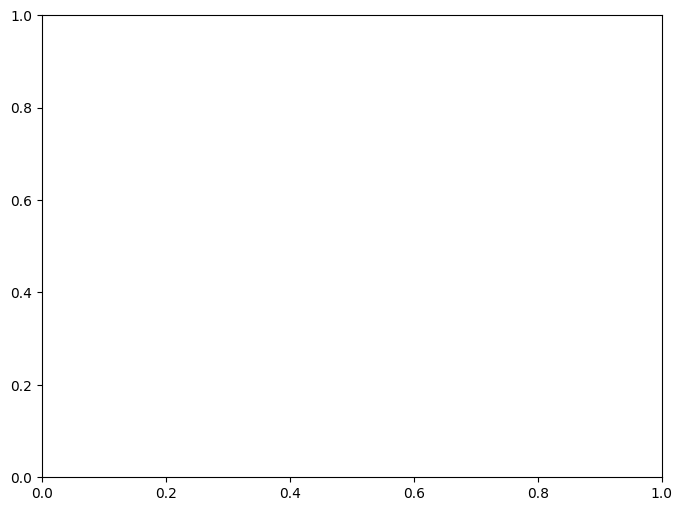

In [10]:
# TODO: maak een 2D- en 3D-plot van de voornaamste PCA-componenten van de
# trainingrijen van X_scaled (niet gecheckt, maar leerzaam).
# === TODO 2: 2D- en 3D-plot van de trainingrijen ===
import matplotlib.pyplot as plt

# Selecteer alleen de trainingsrijen uit de geschaalde data
aantal_train_rijen = len(X_train)
X_scaled_train = X_scaled[:aantal_train_rijen]

# --- 2D PLOT ---
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled_train)

plt.figure(figsize=(8, 6))
# We gebruiken y_train om de punten te kleuren
plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=y_train, cmap='viridis', alpha=0.7)
plt.title("2D PCA Plot van APS Training Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Klasse (y_train)")
plt.show()

# --- 3D PLOT ---
pca_3 = PCA(n_components=3)
X_pca_3 = pca_3.fit_transform(X_scaled_train)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_pca_3[:, 0], X_pca_3[:, 1], X_pca_3[:, 2], c=y_train, cmap='viridis', alpha=0.7)
ax.set_title("3D PCA Plot van APS Training Data")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_zlabel("PC 3")
fig.colorbar(scatter, label="Klasse (y_train)")
plt.show()

## Meerkeuzevragen

### Vraag 1 — Standaardiseren
Waarom moet je de features **standaardiseren** vóór je PCA toepast?

- **A)** Omdat PCA alleen werkt op gehele getallen.
- **B)** Omdat features op verschillende schalen anders onevenredig veel gewicht krijgen en de PCA dan vooral de grote schalen weerspiegelt.
- **C)** Omdat standaardiseren het aantal features vermindert.
- **D)** Omdat standaardiseren automatisch 95% van de variantie behoudt.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_scaling`.

### Vraag 2 — n_components=0.95
Wat betekent `PCA(n_components=0.95)`?

- **A)** Het model houdt 95 van de oorspronkelijke features over.
- **B)** Het model houdt 95% van de datapunten over.
- **C)** Het model kiest het kleinste aantal componenten dat samen minstens 95% van de variantie verklaart.
- **D)** Het model kiest altijd exact 95 componenten.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_95`.


In [ ]:
# Vraag 1: antwoord_scaling = "A", "B", "C" of "D"
antwoord_scaling = "B"

# Vraag 2: antwoord_95 = "A", "B", "C" of "D"
antwoord_95 = "C"
